In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency
import seaborn as sns

# Load the dataset
df = pd.read_csv(r"C:\Users\fabia\Documents\Ironhack ALL\Coursework\W5\Dataset\amz_uk_price_prediction_dataset.csv")




In [5]:
print(df['isBestSeller'].unique())

[False  True]


In [3]:
crosstab = pd.crosstab(df['category'], df['isBestSeller'])

# Replace `1` and `0` with the correct column names based on your data
# For example, if the unique values in `isBestSeller` are True/False:
if True in crosstab.columns and False in crosstab.columns:
    crosstab['ProportionBestSeller'] = crosstab[True] / (crosstab[True] + crosstab[False])
elif 'Yes' in crosstab.columns and 'No' in crosstab.columns:
    crosstab['ProportionBestSeller'] = crosstab['Yes'] / (crosstab['Yes'] + crosstab['No'])
else:
    print("Unexpected column names in crosstab:", crosstab.columns)

# Sort by the new column
crosstab_sorted = crosstab.sort_values(by='ProportionBestSeller', ascending=False)

print("Crosstab of Category and Best-Seller Status:")
print(crosstab_sorted)


Crosstab of Category and Best-Seller Status:
isBestSeller                      False  True  ProportionBestSeller
category                                                           
Grocery                            9008   556              0.058135
Smart Home Security & Lighting       98     6              0.057692
Health & Personal Care             9017   552              0.057686
Mobile Phone Accessories            248    11              0.042471
Power & Hand Tools                 8353   306              0.035339
...                                 ...   ...                   ...
CD, Disc & Tape Players            8798     0              0.000000
General Music-Making Accessories    259     0              0.000000
Snowboard Boots                    1449     0              0.000000
Boxes & Organisers                  911     0              0.000000
eBook Readers & Accessories         246     0              0.000000

[296 rows x 3 columns]


In [6]:
# Step 2: Statistical Tests
chi2, p, dof, expected = chi2_contingency(pd.crosstab(df['category'], df['isBestSeller']))
print("\nChi-square Test Results:")
print(f"Chi-square Statistic: {chi2}")
print(f"P-value: {p}")
print(f"Degrees of Freedom: {dof}")




Chi-square Test Results:
Chi-square Statistic: 36540.20270061387
P-value: 0.0
Degrees of Freedom: 295


In [7]:
# Cramér's V
n = df.shape[0]
cramers_v = np.sqrt(chi2 / (n * (min(crosstab.shape) - 1)))
print(f"Cramér's V: {cramers_v}")



Cramér's V: 0.08646709890892415


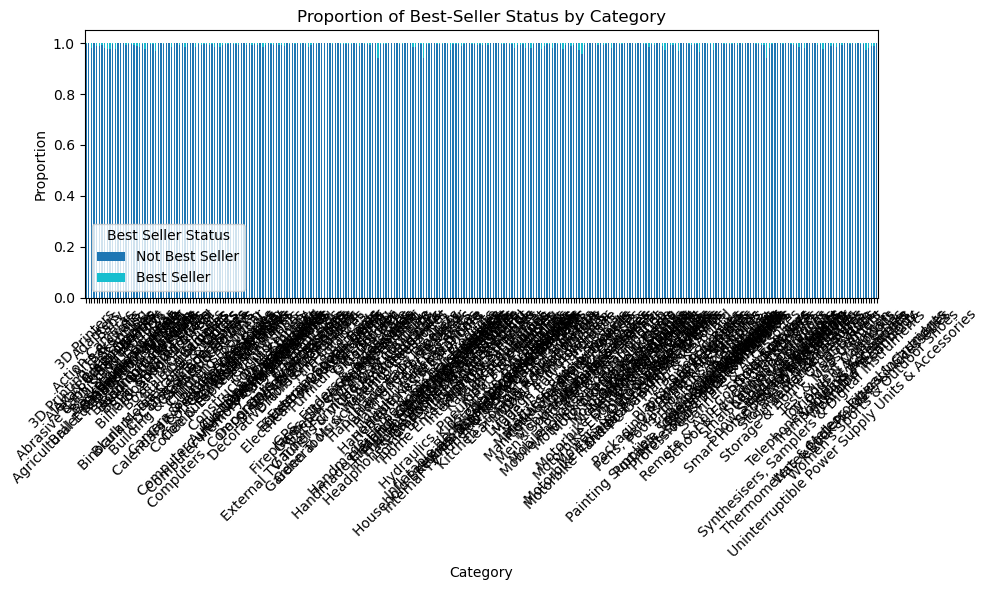

In [8]:
# Step 3: Visualization
crosstab_normalized = pd.crosstab(df['category'], df['isBestSeller'], normalize='index')

crosstab_normalized.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 6),
    colormap="tab10"
)
plt.title("Proportion of Best-Seller Status by Category")
plt.xlabel("Category")
plt.ylabel("Proportion")
plt.legend(title="Best Seller Status", labels=["Not Best Seller", "Best Seller"])
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [9]:
q1 = df['price'].quantile(0.25)
q3 = df['price'].quantile(0.75)
iqr = q3 - q1


In [10]:
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

In [11]:
df_no_outliers = df[(df['price'] >= lower_bound) & (df['price'] <= upper_bound)]


In [12]:
top_20_categories = df_no_outliers['category'].value_counts().head(20).index
filtered_data = df_no_outliers[df_no_outliers['category'].isin(top_20_categories)]


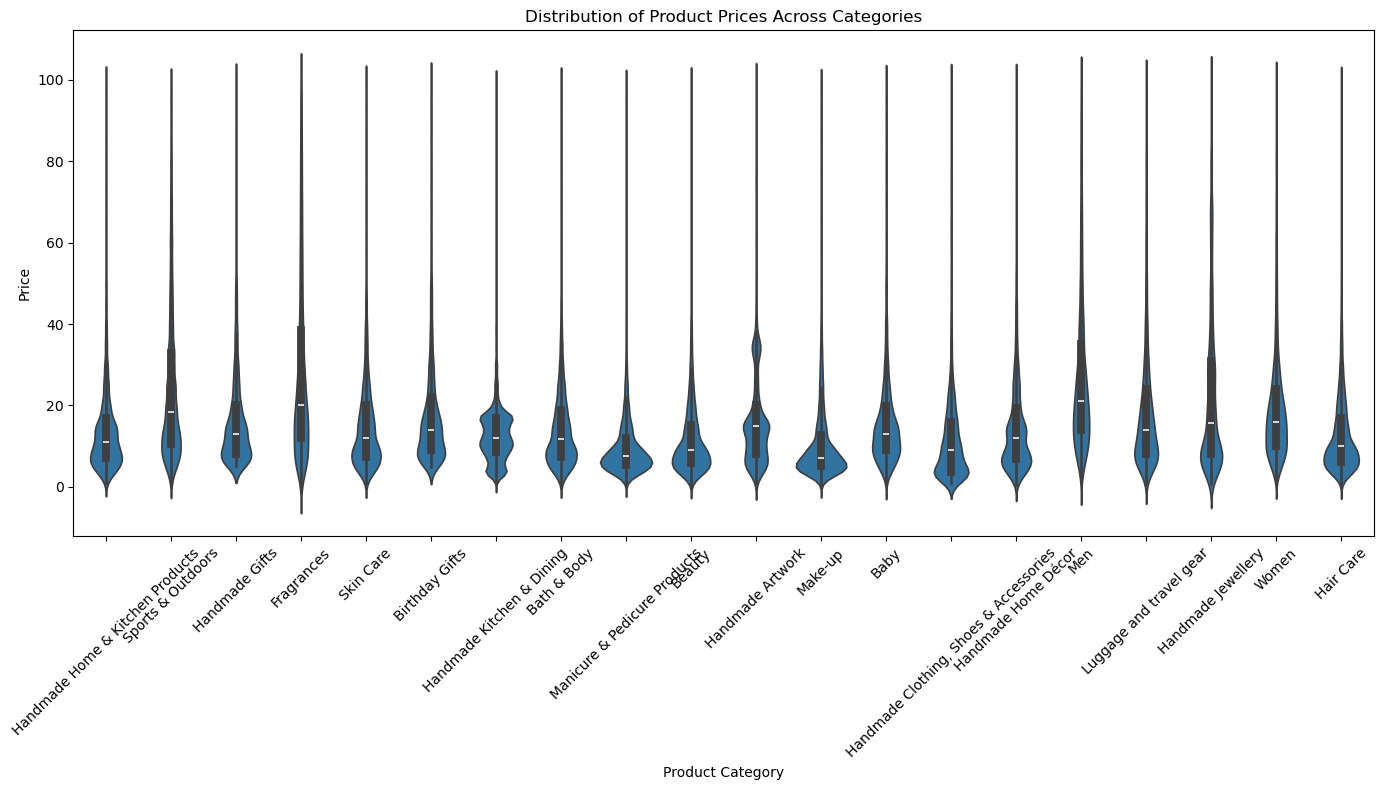

In [13]:
plt.figure(figsize=(14, 8))
sns.violinplot(data=filtered_data, x='category', y='price')
plt.xticks(rotation=45)
plt.title("Distribution of Product Prices Across Categories")
plt.xlabel("Product Category")
plt.ylabel("Price")
plt.tight_layout()
plt.show()


In [14]:
top_10_categories = df_no_outliers['category'].value_counts().head(10).index


In [15]:
avg_price_by_category = df_no_outliers[df_no_outliers['category'].isin(top_10_categories)].groupby('category')['price'].mean()


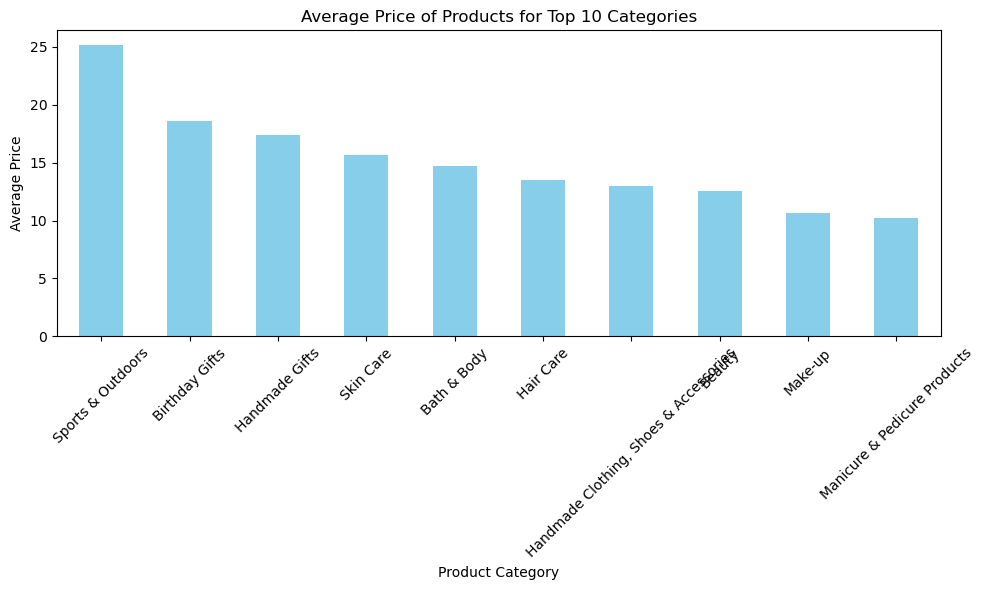

In [16]:
plt.figure(figsize=(10, 6))
avg_price_by_category.sort_values(ascending=False).plot(kind='bar', color='skyblue')
plt.title("Average Price of Products for Top 10 Categories")
plt.xlabel("Product Category")
plt.ylabel("Average Price")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


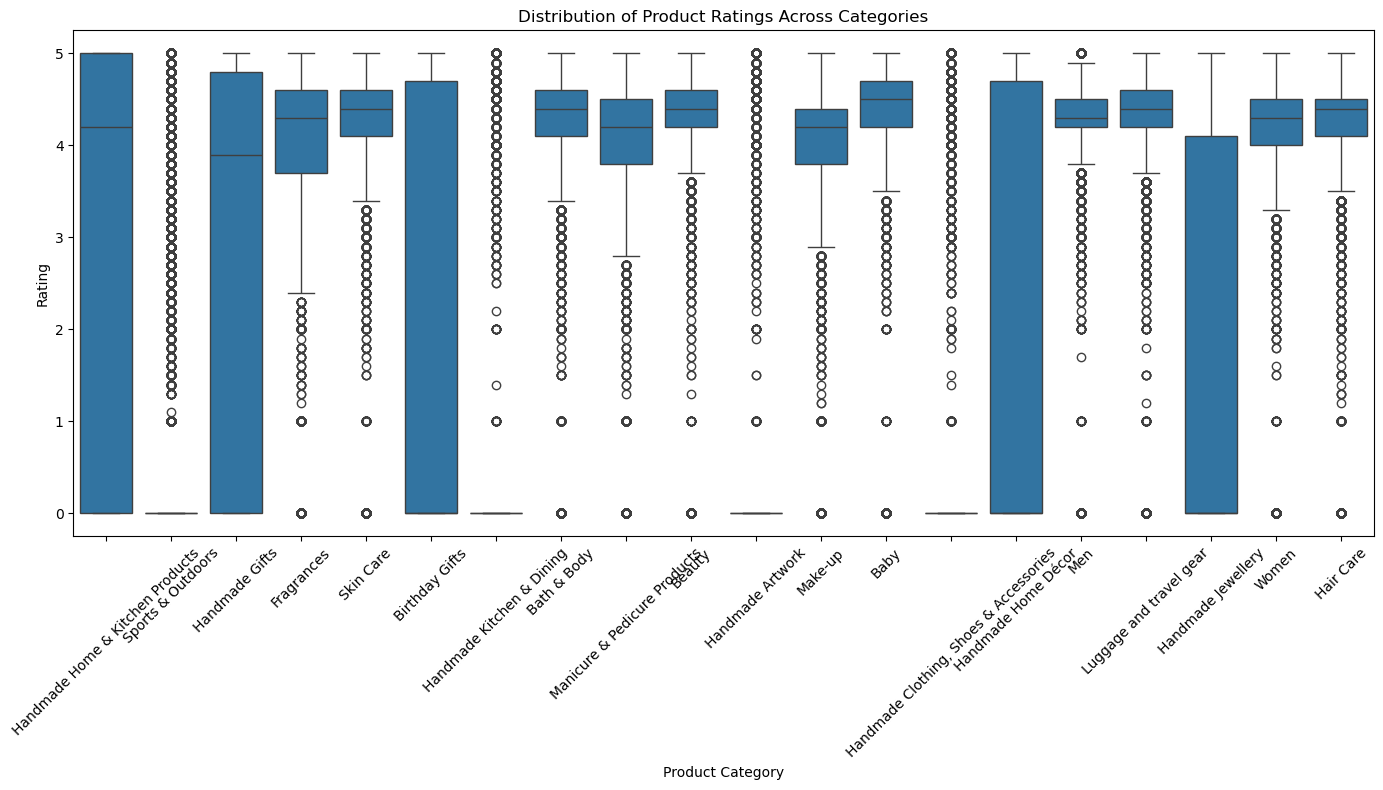

In [17]:
plt.figure(figsize=(14, 8))
sns.boxplot(data=filtered_data, x='category', y='stars')
plt.xticks(rotation=45)
plt.title("Distribution of Product Ratings Across Categories")
plt.xlabel("Product Category")
plt.ylabel("Rating")
plt.tight_layout()
plt.show()
